# Legal Corpus Visualization & Data Understanding

**Project:** PDPL Compliance Copilot  
**Corpus:** PDPL + Implementing Regulations (IR) + Transfer Regulation (TR)

This notebook explores the approved legal corpus before it is used by the RAG pipeline.

## Goals
- Confirm corpus structure and completeness.
- Visualize documents and languages.
- Analyse article/text length.
- Identify the longest articles.
- Run basic data-quality checks.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [
    Path("data/processed/legal_articles_v1.0.csv"),
    Path("../data/processed/legal_articles_v1.0.csv"),
]

DATA_PATH = next((p for p in candidates if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find legal_articles_v1.0.csv. "
        "Check data/processed/."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")


Loaded: ..\data\processed\legal_articles_v1.0.csv
Rows: 180
Columns: 12


## 1. Dataset preview

Each row represents one legal article in one language.


In [2]:
df.head()


,record_id,document_code,document_name,article_number,article_title,language,official_text,normalized_text,source_entity,source_url,verification_source,verification_url
0,PDPL-A01-AR,PDPL,نظام حماية البيانات الشخصية,1,NaN,ar,لغرض تطبيق هذا النظام، يُقصد بالألفاظ والعبارا...,لغرض تطبيق هذا النظام، يقصد بالالفاظ والعبارات...,الهيئة السعودية للبيانات والذكاء الاصطناعي (سد...,https://dgp.sdaia.gov.sa/wps/portal/pdp/knowle...,هيئة الخبراء بمجلس الوزراء,https://laws.boe.gov.sa/BoeLaws/Laws/LawDetail...
1,PDPL-A02-AR,PDPL,نظام حماية البيانات الشخصية,2,NaN,ar,1- يُطبق النظام على أي عملية مُعالجة لبيانات ش...,1- يطبق النظام علي اي عمليه معالجه لبيانات شخص...,الهيئة السعودية للبيانات والذكاء الاصطناعي (سد...,https://dgp.sdaia.gov.sa/wps/portal/pdp/knowle...,هيئة الخبراء بمجلس الوزراء,https://laws.boe.gov.sa/BoeLaws/Laws/LawDetail...
2,PDPL-A03-AR,PDPL,نظام حماية البيانات الشخصية,3,NaN,ar,لا تخل الأحكام والإجراءات المنصوص عليها في الن...,لا تخل الاحكام والاجراءات المنصوص عليها في الن...,الهيئة السعودية للبيانات والذكاء الاصطناعي (سد...,https://dgp.sdaia.gov.sa/wps/portal/pdp/knowle...,هيئة الخبراء بمجلس الوزراء,https://laws.boe.gov.sa/BoeLaws/Laws/LawDetail...
3,PDPL-A04-AR,PDPL,نظام حماية البيانات الشخصية,4,NaN,ar,يكون لصاحب البيانات الشخصية -وفقاً للأحكام الو...,يكون لصاحب البيانات الشخصيه -وفقا للاحكام الوا...,الهيئة السعودية للبيانات والذكاء الاصطناعي (سد...,https://dgp.sdaia.gov.sa/wps/portal/pdp/knowle...,هيئة الخبراء بمجلس الوزراء,https://laws.boe.gov.sa/BoeLaws/Laws/LawDetail...
4,PDPL-A05-AR,PDPL,نظام حماية البيانات الشخصية,5,NaN,ar,1- فيما عدا الأحوال المنصوص عليها في النظام، ل...,1- فيما عدا الاحوال المنصوص عليها في النظام، ل...,الهيئة السعودية للبيانات والذكاء الاصطناعي (سد...,https://dgp.sdaia.gov.sa/wps/portal/pdp/knowle...,هيئة الخبراء بمجلس الوزراء,https://laws.boe.gov.sa/BoeLaws/Laws/LawDetail...


## 2. Corpus structure by document and language


In [3]:
doc_lang_counts = (
    df.groupby(["document_code", "language"])
      .size()
      .unstack(fill_value=0)
)
doc_lang_counts


language,ar,en
document_code,,
IR,38,38
PDPL,43,43
TR,9,9


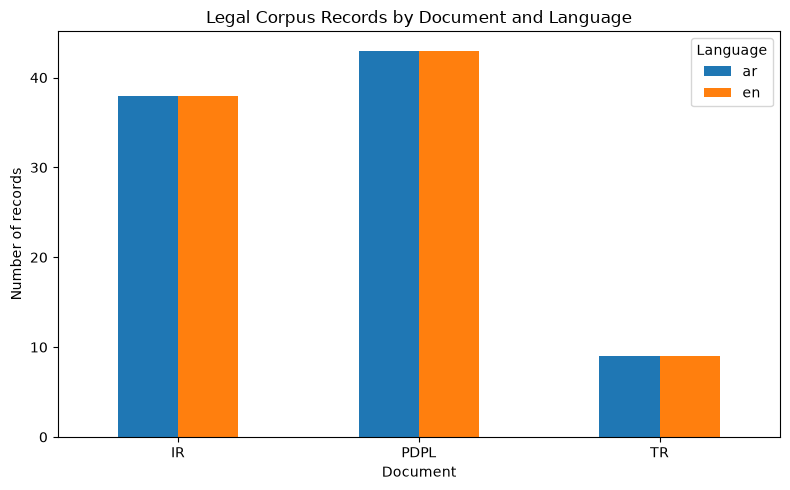

In [4]:
ax = doc_lang_counts.plot(kind="bar", figsize=(8, 5))
ax.set_title("Legal Corpus Records by Document and Language")
ax.set_xlabel("Document")
ax.set_ylabel("Number of records")
ax.legend(title="Language")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Interpretation

Arabic and English should be balanced for each document.  
This is important because the copilot must support both Arabic and English retrieval.


## 3. Number of unique articles per document


In [5]:
article_counts = (
    df.groupby("document_code")["article_number"]
      .nunique()
      .sort_values(ascending=False)
)
article_counts


document_code
PDPL    43
IR      38
TR       9
Name: article_number, dtype: int64

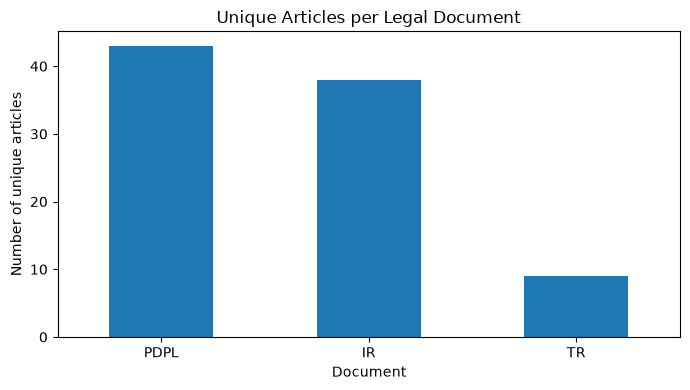

In [6]:
ax = article_counts.plot(kind="bar", figsize=(7, 4))
ax.set_title("Unique Articles per Legal Document")
ax.set_xlabel("Document")
ax.set_ylabel("Number of unique articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. Text-length analysis

Longer articles may contain more clauses and can be harder for retrieval and generation.


In [7]:
df["char_count"] = df["official_text"].fillna("").str.len()
df["word_count"] = df["official_text"].fillna("").str.split().str.len()

df[["char_count", "word_count"]].describe().round(1)


,char_count,word_count
count,180.0,180.0
mean,888.6,142.8
std,727.9,115.6
min,7.0,1.0
25%,354.8,57.8
50%,681.0,114.0
75%,1205.0,190.0
max,3782.0,552.0


In [8]:
length_summary = (
    df.groupby(["document_code", "language"])[["char_count", "word_count"]]
      .agg(["mean", "median", "min", "max"])
      .round(1)
)
length_summary


char_count                    word_count             \
                             mean  median  min   max       mean median min   
document_code language                                                       
IR            ar            976.5   851.5   97  2808      159.8  140.0  16   
              en           1230.3  1045.5  178  3418      192.3  156.5  26   
PDPL          ar            565.8   509.0    7  3098       95.9   85.0   1   
              en            753.7   675.0    9  3782      119.5  107.0   1   
TR            ar            944.3   478.0   50  2500      153.7   83.0   8   
              en           1204.4   582.0   93  3197      186.6   92.0  16   

                             
                        max  
document_code language       
IR            ar        468  
              en        546  
PDPL          ar        512  
              en        552  
TR            ar        419  
              en        511

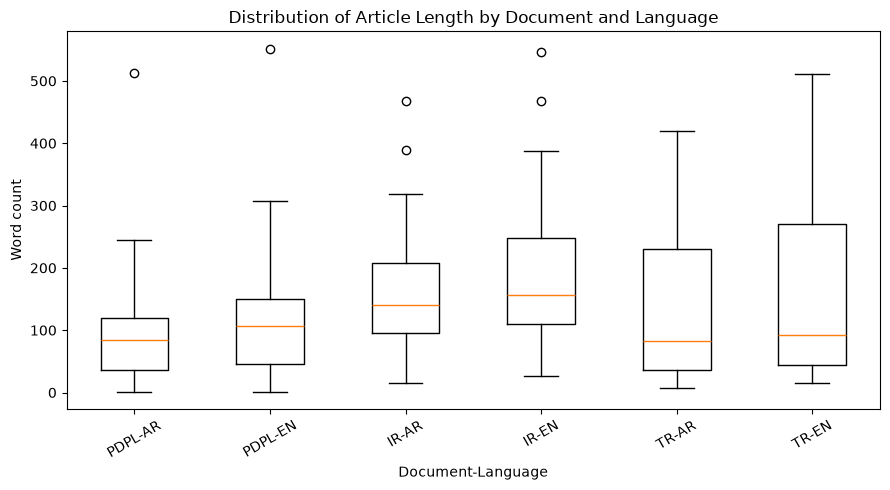

In [9]:
groups = []
labels = []

for document in ["PDPL", "IR", "TR"]:
    for language in ["ar", "en"]:
        values = df.loc[
            (df["document_code"] == document) & (df["language"] == language),
            "word_count"
        ]
        if not values.empty:
            groups.append(values)
            labels.append(f"{document}-{language.upper()}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(groups, tick_labels=labels)
ax.set_title("Distribution of Article Length by Document and Language")
ax.set_xlabel("Document-Language")
ax.set_ylabel("Word count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 5. Longest articles


In [10]:
longest = (
    df.sort_values("word_count", ascending=False)
      [["record_id", "document_code", "article_number", "language", "word_count"]]
      .head(15)
      .reset_index(drop=True)
)
longest


,record_id,document_code,article_number,language,word_count
0,PDPL-A01-EN,PDPL,1,en,552
1,IR-A04-EN,IR,4,en,546
2,PDPL-A01-AR,PDPL,1,ar,512
3,TR-A04-EN,TR,4,en,511
4,IR-A24-EN,IR,24,en,468
5,IR-A04-AR,IR,4,ar,468
6,TR-A04-AR,TR,4,ar,419
7,TR-A03-EN,TR,3,en,400
8,IR-A24-AR,IR,24,ar,389
9,IR-A25-EN,IR,25,en,387


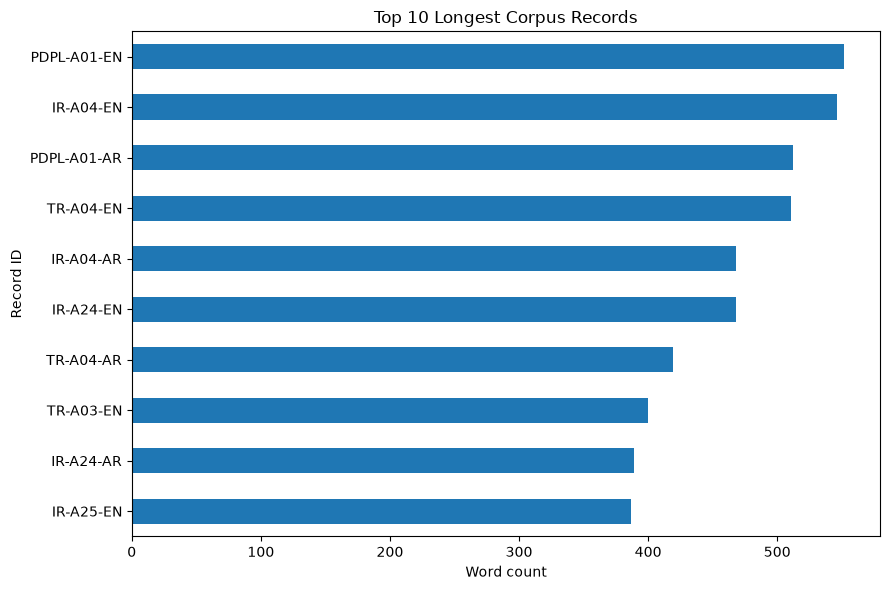

In [11]:
top10 = longest.head(10).copy()

ax = top10.sort_values("word_count").plot(
    x="record_id",
    y="word_count",
    kind="barh",
    legend=False,
    figsize=(9, 6)
)
ax.set_title("Top 10 Longest Corpus Records")
ax.set_xlabel("Word count")
ax.set_ylabel("Record ID")
plt.tight_layout()
plt.show()


## 6. Data-quality checks

These checks complement the extraction report and manual QA workbook.


In [12]:
quality_checks = pd.DataFrame({
    "Check": [
        "Total records",
        "Duplicate record_id",
        "Missing official_text",
        "Missing normalized_text",
        "Missing document_code",
        "Missing article_number",
        "Arabic records",
        "English records",
    ],
    "Value": [
        len(df),
        int(df["record_id"].duplicated().sum()),
        int((df["official_text"].fillna("").str.strip() == "").sum()),
        int((df["normalized_text"].fillna("").str.strip() == "").sum()),
        int(df["document_code"].isna().sum()),
        int(df["article_number"].isna().sum()),
        int((df["language"] == "ar").sum()),
        int((df["language"] == "en").sum()),
    ]
})
quality_checks


,Check,Value
0,Total records,180
1,Duplicate record_id,0
2,Missing official_text,0
3,Missing normalized_text,0
4,Missing document_code,0
5,Missing article_number,0
6,Arabic records,90
7,English records,90


## 7. Final corpus summary


In [13]:
summary = {
    "Total language records": len(df),
    "Unique article pairs": df.groupby(["document_code", "article_number"]).ngroups,
    "Documents": sorted(df["document_code"].dropna().unique().tolist()),
    "Languages": sorted(df["language"].dropna().unique().tolist()),
    "Duplicate record IDs": int(df["record_id"].duplicated().sum()),
}
summary


{'Total language records': 180,
 'Unique article pairs': 90,
 'Documents': ['IR', 'PDPL', 'TR'],
 'Languages': ['ar', 'en'],
 'Duplicate record IDs': 0}

## Conclusion

Expected approved v1.0 structure:

- **PDPL:** 43 Arabic + 43 English
- **IR:** 38 Arabic + 38 English
- **TR:** 9 Arabic + 9 English
- **Total:** 180 language records / 90 bilingual article pairs

The corpus was also manually reviewed before use in retrieval and RAG experiments.
